<a href="https://colab.research.google.com/github/ashrita948/EDA/blob/main/Ashrita_Cars_EDA_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [99]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [100]:
from google.colab import files

uploaded = files.upload()

csv_file = next(iter(uploaded))

df = pd.read_csv(csv_file)

Saving used_cars_data.csv to used_cars_data (1).csv


In [101]:
df.head()

,S.No.,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
0,0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.6 km/kg,998 CC,58.16 bhp,5.0,NaN,1.75
1,1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.0,NaN,12.50
2,2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.2 kmpl,1199 CC,88.7 bhp,5.0,8.61 Lakh,4.50
3,3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.0,NaN,6.00
4,4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.0,NaN,17.74


In [102]:
df.tail()

,S.No.,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
7248,7248,Volkswagen Vento Diesel Trendline,Hyderabad,2011,89411,Diesel,Manual,First,20.54 kmpl,1598 CC,103.6 bhp,5.0,NaN,NaN
7249,7249,Volkswagen Polo GT TSI,Mumbai,2015,59000,Petrol,Automatic,First,17.21 kmpl,1197 CC,103.6 bhp,5.0,NaN,NaN
7250,7250,Nissan Micra Diesel XV,Kolkata,2012,28000,Diesel,Manual,First,23.08 kmpl,1461 CC,63.1 bhp,5.0,NaN,NaN
7251,7251,Volkswagen Polo GT TSI,Pune,2013,52262,Petrol,Automatic,Third,17.2 kmpl,1197 CC,103.6 bhp,5.0,NaN,NaN
7252,7252,Mercedes-Benz E-Class 2009-2013 E 220 CDI Avan...,Kochi,2014,72443,Diesel,Automatic,First,10.0 kmpl,2148 CC,170 bhp,5.0,NaN,NaN


In [103]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7253 entries, 0 to 7252
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   S.No.              7253 non-null   int64  
 1   Name               7253 non-null   object 
 2   Location           7253 non-null   object 
 3   Year               7253 non-null   int64  
 4   Kilometers_Driven  7253 non-null   int64  
 5   Fuel_Type          7253 non-null   object 
 6   Transmission       7253 non-null   object 
 7   Owner_Type         7253 non-null   object 
 8   Mileage            7251 non-null   object 
 9   Engine             7207 non-null   object 
 10  Power              7207 non-null   object 
 11  Seats              7200 non-null   float64
 12  New_Price          1006 non-null   object 
 13  Price              6019 non-null   float64
dtypes: float64(2), int64(3), object(9)
memory usage: 793.4+ KB


In [104]:
df.duplicated().sum()

np.int64(0)

In [105]:
df.isnull().sum()

,0
S.No.,0
Name,0
Location,0
Year,0
Kilometers_Driven,0
Fuel_Type,0
Transmission,0
Owner_Type,0
Mileage,2
Engine,46


In [106]:
#categorical
df = df.fillna(df.mode().iloc[0])

In [107]:
#numerical
num =  df.select_dtypes(include ='number').columns
df[num] = df[num].fillna(df[num].median())

In [108]:
df.isnull().sum()

,0
S.No.,0
Name,0
Location,0
Year,0
Kilometers_Driven,0
Fuel_Type,0
Transmission,0
Owner_Type,0
Mileage,0
Engine,0


In [109]:
df.select_dtypes(include = ["int64","float64"]).columns

Index(['S.No.', 'Year', 'Kilometers_Driven', 'Seats', 'Price'], dtype='object')

In [110]:
df.select_dtypes(include=["object"]).columns


Index(['Name', 'Location', 'Fuel_Type', 'Transmission', 'Owner_Type',
       'Mileage', 'Engine', 'Power', 'New_Price'],
      dtype='object')

In [111]:
print(df['Price'].describe())
print(df['Kilometers_Driven'].describe())

count    7253.000000
mean        8.632279
std        10.362044
min         0.440000
25%         3.850000
50%         4.650000
75%         8.400000
max       160.000000
Name: Price, dtype: float64
count    7.253000e+03
mean     5.869906e+04
std      8.442772e+04
min      1.710000e+02
25%      3.400000e+04
50%      5.341600e+04
75%      7.300000e+04
max      6.500000e+06
Name: Kilometers_Driven, dtype: float64


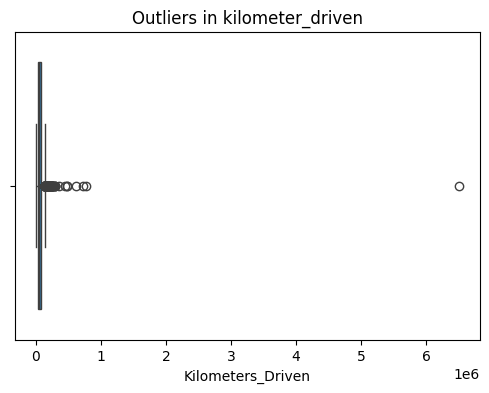

In [112]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df["Kilometers_Driven"])
plt.title("Outliers in kilometer_driven")
plt.show()

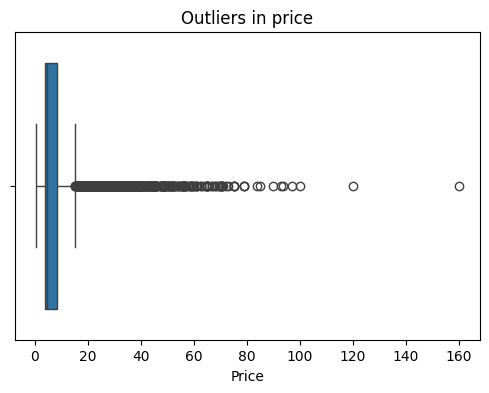

In [113]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df["Price"])
plt.title("Outliers in price")
plt.show()

In [114]:
Q1 = df["Price"].quantile(0.25)
Q3 = df["Price"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [115]:
df["Price"] = df["Price"].clip(lower_bound,upper_bound)

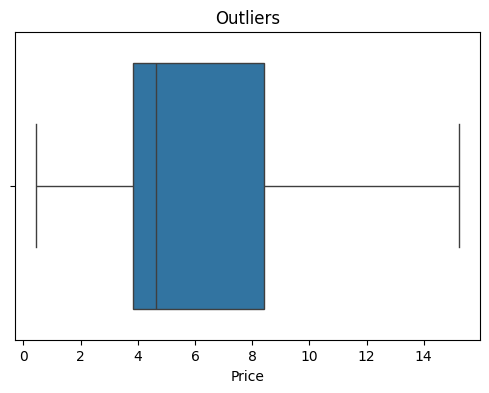

In [116]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df["Price"])
plt.title("Outliers")
plt.show()

In [117]:
print(df['Price'].describe())
print(df['Kilometers_Driven'].describe())


count    7253.000000
mean        6.649657
std         4.291046
min         0.440000
25%         3.850000
50%         4.650000
75%         8.400000
max        15.225000
Name: Price, dtype: float64
count    7.253000e+03
mean     5.869906e+04
std      8.442772e+04
min      1.710000e+02
25%      3.400000e+04
50%      5.341600e+04
75%      7.300000e+04
max      6.500000e+06
Name: Kilometers_Driven, dtype: float64


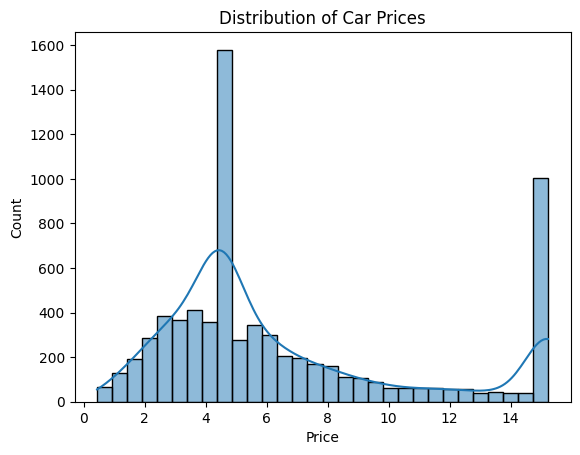

In [118]:
sns.histplot(df["Price"], bins=30, kde=True)
plt.title("Distribution of Car Prices")
plt.show()


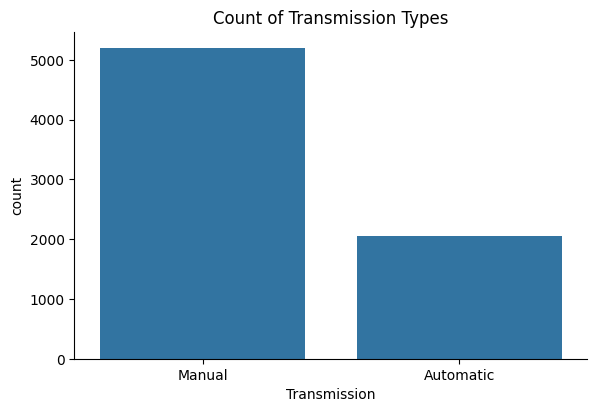

In [119]:
sns.catplot(x="Transmission", kind="count", data=df, height=4, aspect=1.5)
plt.title("Count of Transmission Types")
plt.show()


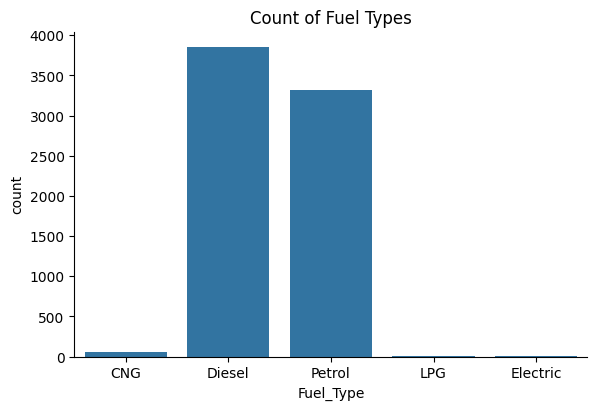

In [120]:
sns.catplot(x="Fuel_Type", kind="count", data=df, height=4, aspect=1.5)
plt.title("Count of Fuel Types")
plt.show()

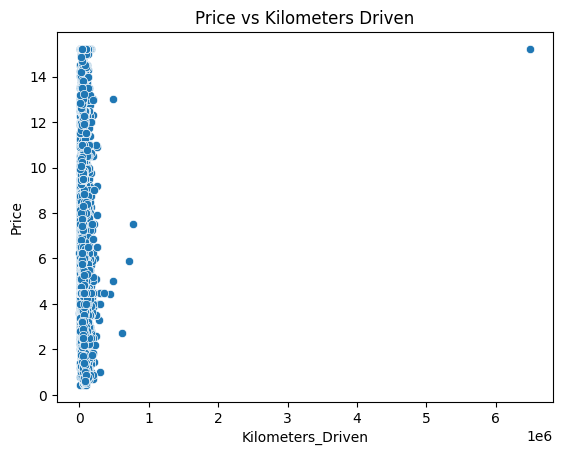

In [121]:
sns.scatterplot(x="Kilometers_Driven", y="Price", data=df)
plt.title("Price vs Kilometers Driven")
plt.show()

Text(0, 0.5, 'Price')

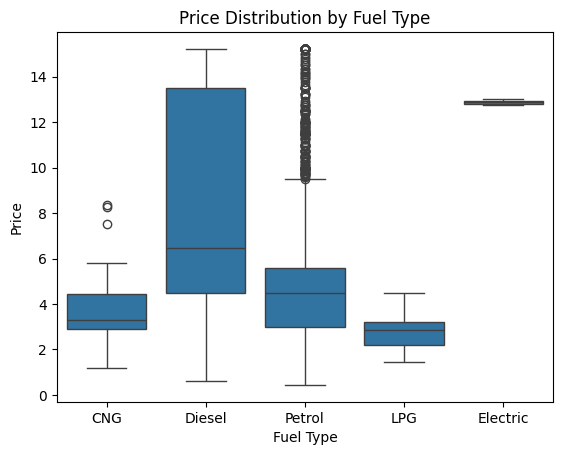

In [122]:
sns.boxplot(x='Fuel_Type', y='Price', data=df)
plt.title("Price Distribution by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Price")


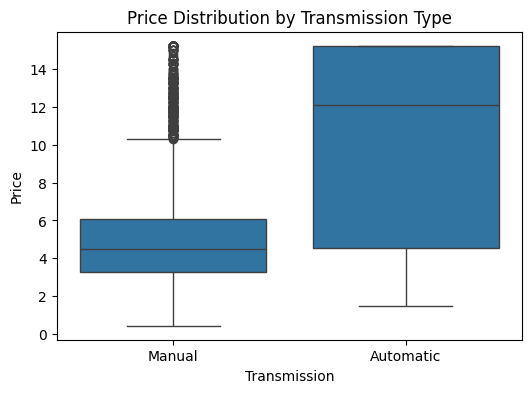

In [123]:
plt.figure(figsize=(6,4))
sns.boxplot(x="Transmission", y="Price", data=df)
plt.title("Price Distribution by Transmission Type")
plt.xlabel("Transmission")
plt.ylabel("Price")
plt.show()


In [124]:
numeric_summary = df.describe()
display(numeric_summary)

,S.No.,Year,Kilometers_Driven,Seats,Price
count,7253.000000,7253.000000,7.253000e+03,7253.000000,7253.000000
mean,3626.000000,2013.365366,5.869906e+04,5.277678,6.649657
std,2093.905084,3.254421,8.442772e+04,0.809039,4.291046
min,0.000000,1996.000000,1.710000e+02,0.000000,0.440000
25%,1813.000000,2011.000000,3.400000e+04,5.000000,3.850000
50%,3626.000000,2014.000000,5.341600e+04,5.000000,4.650000
75%,5439.000000,2016.000000,7.300000e+04,5.000000,8.400000
max,7252.000000,2019.000000,6.500000e+06,10.000000,15.225000


In [125]:
df["Price"].mean()

np.float64(6.649656693781883)

In [126]:
df['Price'].median()

4.65

In [127]:
df['Price'].max()

15.225000000000001

In [128]:
df['Price'].min()

0.44

In [129]:
df['Kilometers_Driven'].max()

6500000

In [130]:
df['Kilometers_Driven'].min()

171

In [131]:
df['Kilometers_Driven'].mean()

np.float64(58699.063146284294)

In [132]:
df['Kilometers_Driven'].median()

53416.0